# Luz Vital - previsão do dia de apagão em massa na área da Enel SP

**Global Solution CitizenTech, FIAP 2026.2, IA & Machine Learning**
Caio Rasuck (RM 93645), Arthur Albuquerque (RM 93025)

Quando um temporal derruba a energia em São Paulo, quem depende dela para viver (oxigênio domiciliar,
insulina na geladeira, cadeira motorizada) não é avisado antes. Este notebook treina um classificador
que diz, para um dia, a probabilidade de ser um **dia de apagão em massa** na área da Enel SP. A
probabilidade vai para a API da Luz Vital (`POST /api/previsoes`), que abre alerta e aciona os
voluntários do bairro.

**Dados reais e públicos** (detalhes em `dados/README.md`):
- ANEEL, *Interrupções de Energia Elétrica nas Redes de Distribuição*, 2019 a 2025, filtrado para a
  Enel SP (CNPJ 61.695.227/0001-93) e só interrupções **não programadas**, agregadas por dia de início.
- INMET, estação automática **A701** (São Paulo, Mirante de Santana), dados horários agregados por dia.

A tabela diária (`dados/processados/diario.csv`) é gerada por `preparar_dados.py` a partir dos arquivos
brutos baixados por `baixar_dados.py`.

> **Premissa de antecedência.** O modelo principal usa o clima *observado* no próprio dia como se fosse a
> *previsão* do tempo para amanhã. Em produção, quem alimenta o modelo é a previsão meteorológica feita
> na véspera, que tem erro. Por isso a seção 9 treina também uma versão que usa só o que já foi
> observado até a véspera, para medir quanto desempenho depende dessa premissa.

In [1]:
import warnings
from pathlib import Path

import joblib
import json
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from luzvital import CLIMA, montar_atributos, montar_atributos_vespera, para_probabilidade_api

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

# Paleta: azul para a série principal, laranja para apagão/limite, cinza para contexto
AZUL, LARANJA, CINZA, CINZA_CLARO = "#2a78d6", "#eb6834", "#8a8984", "#d9d8d4"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

diario = pd.read_csv("dados/processados/diario.csv", parse_dates=["data"], index_col="data")
inmet_bruto = pd.read_csv("dados/processados/inmet_diario.csv", parse_dates=["data"], index_col="data")
print(f"{len(diario)} dias, de {diario.index.min():%d/%m/%Y} a {diario.index.max():%d/%m/%Y}")
diario.head()

2557 dias, de 01/01/2019 a 31/12/2025


,ucs_atingidas,n_interrupcoes,ucs_expurgo_dia_critico,rajada_max_ms,vento_max_ms,chuva_mm,pressao_min_mb,queda_pressao_mb,temp_max_c,umid_min_pct,horas_com_dado,falha_anemometro
data,,,,,,,,,,,,
2019-01-01,98035,483,0,9.3,3.4,6.6,923.9,2.3,32.2,35.0,24,0
2019-01-02,152303,801,132,11.4,3.7,0.0,924.2,2.1,32.1,34.0,24,0
2019-01-03,159620,884,3309,13.5,5.9,36.0,922.0,2.1,33.4,34.0,24,0
2019-01-04,110555,1009,0,11.4,4.8,17.4,922.9,2.7,29.7,53.0,24,0
2019-01-05,183471,967,3150,8.5,4.0,19.4,923.8,2.2,24.6,66.0,24,0


## 1. O rótulo: o que é um "dia de apagão"

**Dia de apagão = total de unidades consumidoras (UCs) atingidas por interrupções não programadas que
começaram naquele dia acima do percentil 97.** O percentil é calculado **só no período de treino
(2019 a 2023)**, para que o teste não influencie a definição do rótulo.

In [2]:
FIM_TREINO = "2023-12-31"
eh_treino = diario.index <= FIM_TREINO

LIMITE_UCS = diario.loc[eh_treino, "ucs_atingidas"].quantile(0.97)
diario["apagao"] = (diario["ucs_atingidas"] > LIMITE_UCS).astype(int)

print(f"Limite (p97 do treino): {LIMITE_UCS:,.0f} UCs atingidas no dia".replace(",", "."))
print(f"Dias de apagão: {diario['apagao'].sum()} no total | "
      f"treino {diario.loc[eh_treino, 'apagao'].sum()} de {eh_treino.sum()} "
      f"({diario.loc[eh_treino, 'apagao'].mean():.1%}) | "
      f"teste {diario.loc[~eh_treino, 'apagao'].sum()} de {(~eh_treino).sum()} "
      f"({diario.loc[~eh_treino, 'apagao'].mean():.1%})")

Limite (p97 do treino): 316.591 UCs atingidas no dia
Dias de apagão: 100 no total | treino 55 de 1826 (3.0%) | teste 45 de 731 (6.2%)


**Conferência com os eventos conhecidos.** Os três grandes apagões recentes em São Paulo precisam cair
como positivos.

In [3]:
EVENTOS = {"2023-11-03": "Temporal de 03/11/2023", "2024-10-11": "Temporal de 11/10/2024",
           "2025-12-10": "Ventania de 10/12/2025"}
ranking = diario["ucs_atingidas"].rank(ascending=False).astype(int)
pd.DataFrame([{
    "evento": nome, "data": data, "UCs atingidas": f"{diario.loc[data, 'ucs_atingidas']:,}".replace(",", "."),
    "posição na série (de 2.557 dias)": ranking[data], "rótulo": diario.loc[data, "apagao"],
} for data, nome in EVENTOS.items()])

,evento,data,UCs atingidas,posição na série (de 2.557 dias),rótulo
0,Temporal de 03/11/2023,2023-11-03,2.559.278,3,1
1,Temporal de 11/10/2024,2024-10-11,3.063.592,2,1
2,Ventania de 10/12/2025,2025-12-10,4.204.739,1,1


## 2. Exploração

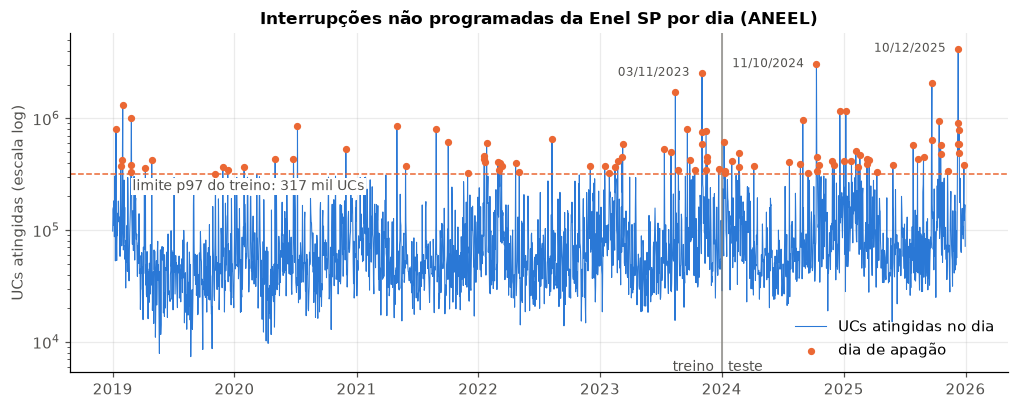

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diario.index, diario["ucs_atingidas"], color=AZUL, lw=0.7, label="UCs atingidas no dia")
pos = diario[diario["apagao"] == 1]
ax.scatter(pos.index, pos["ucs_atingidas"], s=14, color=LARANJA, zorder=3, label="dia de apagão")
ax.axhline(LIMITE_UCS, color=LARANJA, ls="--", lw=1)
ax.text(pd.Timestamp("2019-03-01"), LIMITE_UCS * 0.72, f"limite p97 do treino: {LIMITE_UCS/1e3:,.0f} mil UCs".replace(",", "."),
        color="#52514e", fontsize=9, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(pd.Timestamp("2024-01-01"), color=CINZA, lw=1)
ax.text(pd.Timestamp("2024-01-20"), 5.5e3, "teste", color="#52514e", fontsize=9)
ax.text(pd.Timestamp("2023-12-10"), 5.5e3, "treino", color="#52514e", fontsize=9, ha="right")
for data in EVENTOS:
    ax.annotate(pd.Timestamp(data).strftime("%d/%m/%Y"), (pd.Timestamp(data), diario.loc[data, "ucs_atingidas"]),
                xytext=(-8, 0), textcoords="offset points", fontsize=8, color="#52514e", ha="right", va="center")
ax.set_yscale("log")
ax.set_ylabel("UCs atingidas (escala log)")
ax.set_title("Interrupções não programadas da Enel SP por dia (ANEEL)")
ax.legend(loc="lower right", frameon=False)
plt.show()

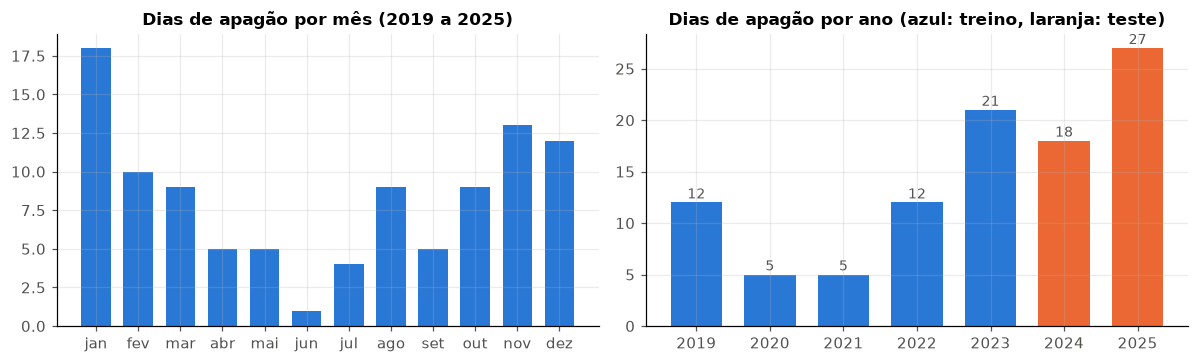

Mediana diária de UCs atingidas por ano (o número de interrupções cresce na série):


data,2019,2020,2021,2022,2023,2024,2025
mediana de UCs/dia,47376,54392,53288,57836,68147,67273,79341


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
por_mes = diario.groupby(diario.index.month)["apagao"].sum()
axs[0].bar(por_mes.index, por_mes.values, color=AZUL, width=0.7)
axs[0].set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
axs[0].set_title("Dias de apagão por mês (2019 a 2025)")
por_ano = diario.groupby(diario.index.year).agg(apagao=("apagao", "sum"), mediana=("ucs_atingidas", "median"))
axs[1].bar(por_ano.index, por_ano["apagao"], color=[AZUL if a <= 2023 else LARANJA for a in por_ano.index], width=0.7)
for a, v in por_ano["apagao"].items():
    axs[1].text(a, v + 0.4, str(v), ha="center", fontsize=9, color="#52514e")
axs[1].set_title("Dias de apagão por ano (azul: treino, laranja: teste)")
plt.tight_layout(); plt.show()

print("Mediana diária de UCs atingidas por ano (o número de interrupções cresce na série):")
por_ano["mediana"].astype(int).to_frame("mediana de UCs/dia").T

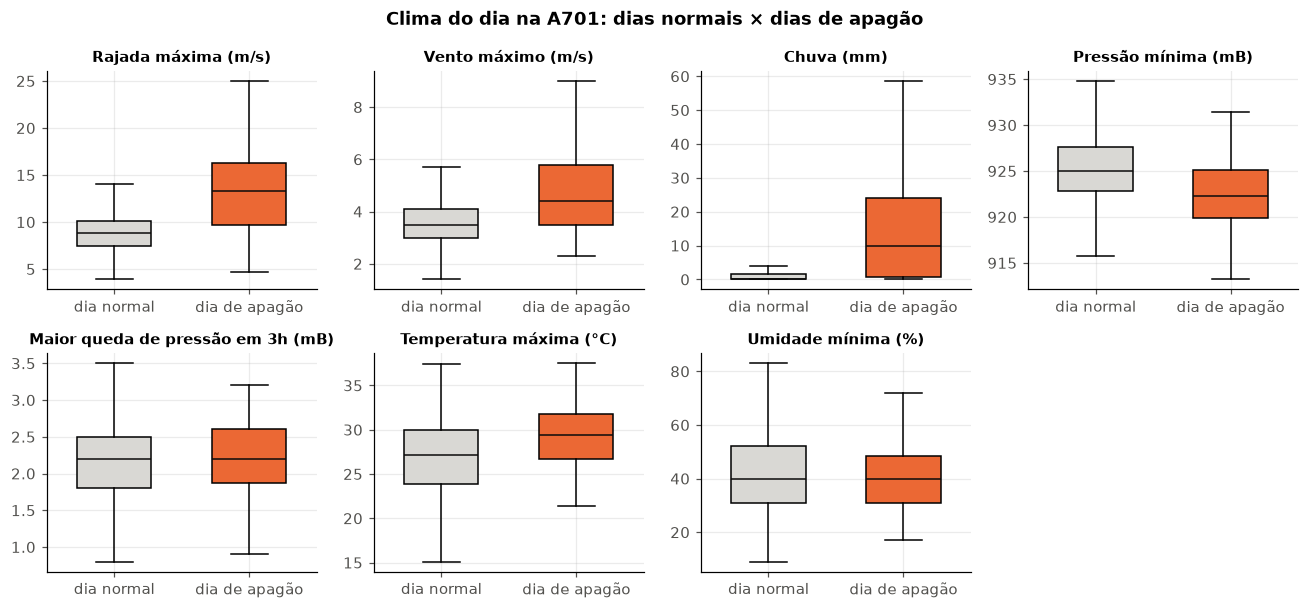

,rajada_max_ms,vento_max_ms,chuva_mm,pressao_min_mb,queda_pressao_mb,temp_max_c,umid_min_pct
apagao,,,,,,,
dia normal,8.8,3.5,0.0,925.0,2.2,27.1,40.0
dia de apagão,13.3,4.4,9.8,922.3,2.2,29.4,40.0


In [6]:
fig, axs = plt.subplots(2, 4, figsize=(12, 5.6))
rotulos = {"rajada_max_ms": "Rajada máxima (m/s)", "vento_max_ms": "Vento máximo (m/s)", "chuva_mm": "Chuva (mm)",
           "pressao_min_mb": "Pressão mínima (mB)", "queda_pressao_mb": "Maior queda de pressão em 3h (mB)",
           "temp_max_c": "Temperatura máxima (°C)", "umid_min_pct": "Umidade mínima (%)"}
for ax, col in zip(axs.flat, CLIMA):
    dados = [diario.loc[diario["apagao"] == k, col].dropna() for k in (0, 1)]
    b = ax.boxplot(dados, widths=0.55, patch_artist=True, showfliers=False, medianprops={"color": "#0b0b0b"})
    for patch, cor in zip(b["boxes"], (CINZA_CLARO, LARANJA)):
        patch.set_facecolor(cor)
    ax.set_xticks([1, 2], ["dia normal", "dia de apagão"])
    ax.set_title(rotulos[col], fontsize=9.5)
axs.flat[-1].axis("off")
fig.suptitle("Clima do dia na A701: dias normais × dias de apagão", fontweight="bold")
plt.tight_layout(); plt.show()

diario.groupby("apagao")[CLIMA].median().rename(index={0: "dia normal", 1: "dia de apagão"}).round(1)

**O que a exploração mostra.**
- Rajada e chuva separam os grupos. Nos dias de apagão a rajada mediana é 13,3 m/s, contra 8,8 nos dias
  normais, e a chuva mediana é 9,8 mm, contra zero. A pressão mínima é um pouco mais baixa (922 contra
  925 mB) e a temperatura máxima um pouco mais alta (29,4 contra 27,1 °C), o padrão de tarde quente antes
  de temporal. A queda de pressão em 3 h e a umidade mínima têm a mesma mediana nos dois grupos.
- 90 dos 100 dias de apagão caem entre outubro e março, mas agosto tem 9 (ventania de frente fria, como
  15/08/2023 com 1,7 milhão de UCs).
- O número de interrupções cresce: a mediana diária foi de 47 mil UCs em 2019 para 79 mil em 2025. Com
  limite fixo, o teste tem 6,2% de dias de apagão contra 3,0% no treino. A seção 10 testa um rótulo que
  acompanha esse crescimento.

## 3. Qualidade dos dados

Três problemas apareceram na conferência dos dados do INMET. Cada um tem uma decisão registrada abaixo.

### 3.1 Anemômetro parado em 2021

Entre 29/03 e 01/09/2021 o anemômetro da A701 falha de forma intermitente: em 106 dos 157 dias o
**vento médio fica em 0,0 m/s o dia inteiro** e a rajada fica entre 0 e 1,6 m/s; nos outros 51 dias
(entre maio e início de julho) as leituras voltam ao normal. O gráfico mostra a rajada diária como veio
do INMET (antes do tratamento).

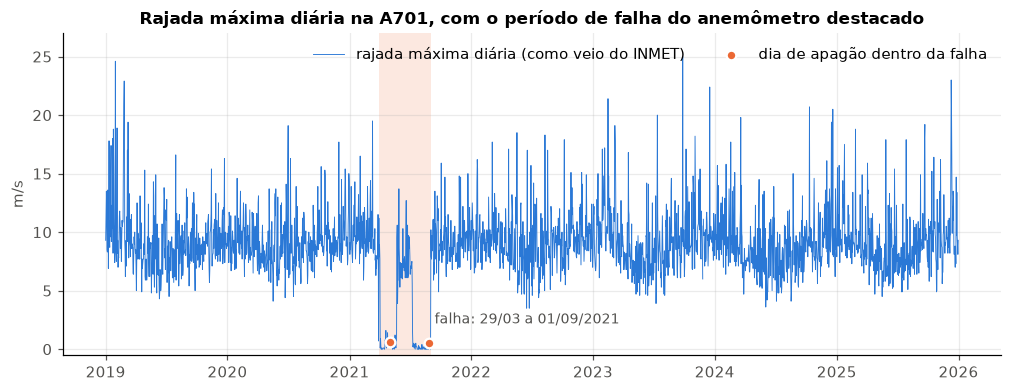

Dias no período: 157, com vento médio 0,0 o dia todo (falha): 106, com leitura normal (mantidos): 51
Rajada nesses dias: de 0.0 a 1.6 m/s
Fora do período: menor rajada diária 3.5 m/s, percentil 1 = 4.7 m/s, mediana 8.8 m/s

Dias de apagão dentro da falha:


,UCs atingidas,rajada registrada (m/s),vento registrado (m/s),chuva (mm)
data,,,,
2021-05-02,853210,0.6,0.0,0.0
2021-08-28,810174,0.5,0.0,37.4


In [7]:
falha = diario["falha_anemometro"] == 1
ini, fim = diario.index[falha].min(), diario.index[falha].max()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(ini, fim, color=LARANJA, alpha=0.15, lw=0)
ax.plot(inmet_bruto.index, inmet_bruto["rajada_max_ms"], color=AZUL, lw=0.6, label="rajada máxima diária (como veio do INMET)")
afetados = diario[falha & (diario["apagao"] == 1)]
ax.scatter(afetados.index, inmet_bruto.loc[afetados.index, "rajada_max_ms"], color=LARANJA, s=40, zorder=3,
           edgecolor="white", lw=1.5, label="dia de apagão dentro da falha")
ax.text(fim + pd.Timedelta(days=12), 2.2, "falha: 29/03 a 01/09/2021", fontsize=9, color="#52514e")
ax.set_ylabel("m/s"); ax.set_ylim(-0.5, 27); ax.set_title("Rajada máxima diária na A701, com o período de falha do anemômetro destacado")
ax.legend(loc="upper right", frameon=False, ncols=2)
plt.show()

fora = inmet_bruto.loc[~inmet_bruto.index.isin(diario.index[falha]), "rajada_max_ms"]
dias_periodo = (diario.index >= ini) & (diario.index <= fim)
print(f"Dias no período: {dias_periodo.sum()}, com vento médio 0,0 o dia todo (falha): {falha.sum()}, com leitura normal (mantidos): {dias_periodo.sum() - falha.sum()}")
print(f"Rajada nesses dias: de {inmet_bruto.loc[falha[falha].index, 'rajada_max_ms'].min()} a "
      f"{inmet_bruto.loc[falha[falha].index, 'rajada_max_ms'].max()} m/s")
print(f"Fora do período: menor rajada diária {fora.min()} m/s, percentil 1 = {fora.quantile(0.01):.1f} m/s, mediana {fora.median():.1f} m/s")
print("\nDias de apagão dentro da falha:")
pd.DataFrame({"UCs atingidas": diario.loc[afetados.index, "ucs_atingidas"],
              "rajada registrada (m/s)": inmet_bruto.loc[afetados.index, "rajada_max_ms"],
              "vento registrado (m/s)": inmet_bruto.loc[afetados.index, "vento_max_ms"],
              "chuva (mm)": diario.loc[afetados.index, "chuva_mm"]})

**Decisão: falha de sensor, não calmaria.** Uma rajada diária abaixo de 2 m/s não acontece em nenhum
outro dia dos 7 anos, e são mais de cinco meses seguidos com vento médio exatamente zero. O INMET gravou
**zero em vez de -9999** (o código de nulo), então o problema não aparece como dado faltante.

- Vento e rajada desses **106 dias** viram **nulos** em `preparar_dados.py` (coluna `falha_anemometro`
  marca os dias). Na conferência inicial contamos 101 dias usando o corte "rajada ≤ 1 m/s"; com a regra
  da falha (vento médio zero o dia inteiro dentro do período) entram mais 5 dias com rajada residual de
  1,2 a 1,6 m/s, que são do mesmo defeito. Os 51 dias do período com leitura normal ficam como estão.
- Esses dias **saem do treino**. Dois deles são dias de apagão (02/05/2021, com 853 mil UCs, e
  28/08/2021, com 810 mil). Se ficassem com vento zero, o modelo aprenderia que dá apagão sem vento; se
  recebessem a mediana, viraram "apagões com vento normal" que não aconteceram.
- O pipeline mantém uma **imputação pela mediana do treino**, só para aguentar nulos na hora da previsão.

### 3.2 Dias sem chuva registrada e dias com poucas horas de dado

In [8]:
sem_chuva = diario[diario["chuva_mm"].isna()]
print(f"Dias sem nenhuma hora de chuva registrada: {len(sem_chuva)} (dias de apagão entre eles: {sem_chuva['apagao'].sum()})")
sem_chuva[["horas_com_dado", "rajada_max_ms", "chuva_mm", "ucs_atingidas", "apagao"]].T

Dias sem nenhuma hora de chuva registrada: 17 (dias de apagão entre eles: 0)


data,2023-08-25,2023-08-26,2023-08-27,2023-08-28,2023-08-29,2023-08-30,2023-08-31,2023-09-01,2023-09-04,2023-09-05,2023-09-06,2023-09-07,2023-09-08,2023-09-09,2023-09-10,2023-09-11,2023-11-27
horas_com_dado,24.0,24.0,24.0,23.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,24.0,0.0
rajada_max_ms,9.1,9.6,8.1,7.0,6.9,9.6,7.3,6.3,12.7,10.3,9.7,8.5,10.8,11.6,6.8,6.1,NaN
chuva_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ucs_atingidas,186852.0,223787.0,52851.0,40669.0,38904.0,47346.0,48749.0,72559.0,52302.0,36832.0,40744.0,43446.0,74560.0,32286.0,20419.0,41390.0,75325.0
apagao,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
poucas_horas = diario[diario["horas_com_dado"] < 18]
print(f"Dias com menos de 18 h de dado: {len(poucas_horas)} (dias de apagão entre eles: {poucas_horas['apagao'].sum()})")
print(f"Dias com 18 a 23 h de dado: {((diario['horas_com_dado'] >= 18) & (diario['horas_com_dado'] < 24)).sum()}")
poucas_horas[["horas_com_dado", "rajada_max_ms", "chuva_mm", "ucs_atingidas", "apagao"]]

Dias com menos de 18 h de dado: 15 (dias de apagão entre eles: 0)
Dias com 18 a 23 h de dado: 81


,horas_com_dado,rajada_max_ms,chuva_mm,ucs_atingidas,apagao
data,,,,,
2023-05-13,17,7.8,0.0,30706,0
2023-05-28,13,9.0,11.4,135394,0
2023-07-09,13,3.9,1.2,99877,0
2023-07-14,15,11.6,0.0,99617,0
2023-07-17,17,7.6,0.0,111521,0
2023-08-05,15,6.4,0.0,52148,0
2023-09-28,17,9.7,0.0,171485,0
2023-09-29,15,8.8,0.0,80153,0
2023-11-21,7,7.7,0.0,57930,0


**Decisão:**
- **17 dias sem chuva** (25/08 a 11/09/2023, um trecho de falha do pluviômetro, e 27/11/2023): ficam na
  base com chuva nula, que a imputação do pipeline preenche com a mediana do treino (0 mm, porque a maior
  parte dos dias não chove). Nenhum deles é dia de apagão, então a imputação não troca nenhum positivo de
  lado. A chuva acumulada dos 3 dias anteriores soma só os dias com dado.
- **15 dias com menos de 18 h de dado**: ficam na base. Os valores do dia são calculados com as horas
  que existem, então a rajada máxima e a chuva total podem estar **subestimadas** nesses dias. Nenhum é dia
  de apagão, e 14 dos 15 estão no treino (2023), em meio a 1.700 dias; o efeito no modelo é pequeno. O
  dia 27/11/2023 (0 h de dado) fica todo nulo e é imputado.

### 3.3 Queda de pressão

A "maior queda de pressão em 3 h no dia" tem a mesma mediana nos dias normais e nos dias de apagão
(gráfico da seção 2). Ela fica no modelo como foi especificada; a explicação está no relatório e na
importância das variáveis (seção 8).

## 4. Atributos e divisão treino/teste

**Atributos do modelo principal** (`luzvital.py`, o mesmo código usado por `enviar_previsao.py`):
- clima do dia: rajada máxima, vento máximo, chuva total, pressão mínima, maior queda de pressão em 3 h,
  temperatura máxima e umidade mínima;
- **mês**, em seno e cosseno (assim dezembro fica perto de janeiro);
- **chuva acumulada dos 3 dias anteriores** (solo encharcado derruba árvore com menos vento).

**Divisão temporal, sem embaralhar:** treino de 2019 a 2023, teste em 2024 e 2025. O teste fica guardado
até a escolha do modelo e do limiar; toda escolha usa só validação cruzada no treino.

In [10]:
X = montar_atributos(diario)
y = diario["apagao"]
ATRIBUTOS = list(X.columns)

no_treino = eh_treino & (diario["falha_anemometro"] == 0)   # tira os 106 dias do anemômetro parado
no_teste = ~eh_treino
X_tr, y_tr = X[no_treino], y[no_treino]
X_te, y_te = X[no_teste], y[no_teste]

print("Atributos:", ATRIBUTOS)
pd.DataFrame({
    "período": ["2019 a 2023 (sem os dias da falha)", "2024 a 2025"],
    "dias": [len(X_tr), len(X_te)],
    "dias de apagão": [int(y_tr.sum()), int(y_te.sum())],
    "% apagão": [f"{y_tr.mean():.1%}", f"{y_te.mean():.1%}"],
}, index=["treino", "teste"])

Atributos: ['rajada_max_ms', 'vento_max_ms', 'chuva_mm', 'pressao_min_mb', 'queda_pressao_mb', 'temp_max_c', 'umid_min_pct', 'chuva_3d_ant', 'mes_sin', 'mes_cos']


,período,dias,dias de apagão,% apagão
treino,2019 a 2023 (sem os dias da falha),1720,53,3.1%
teste,2024 a 2025,731,45,6.2%


**Validação cruzada temporal no treino.** `TimeSeriesSplit` com 4 dobras: cada dobra treina no passado
e valida no período seguinte, nunca o contrário. Com 5 dobras uma delas ficaria com só 2 dias de apagão
para validar.

In [11]:
cv = TimeSeriesSplit(n_splits=4)
pd.DataFrame([{
    "dobra": i + 1,
    "treina até": f"{X_tr.index[a[-1]]:%d/%m/%Y}",
    "valida": f"{X_tr.index[b[0]]:%d/%m/%Y} a {X_tr.index[b[-1]]:%d/%m/%Y}",
    "apagões no treino da dobra": int(y_tr.iloc[a].sum()),
    "apagões na validação": int(y_tr.iloc[b].sum()),
} for i, (a, b) in enumerate(cv.split(X_tr))]).set_index("dobra")

,treina até,valida,apagões no treino da dobra,apagões na validação
dobra,,,,
1,10/12/2019,11/12/2019 a 18/11/2020,11,5
2,18/11/2020,19/11/2020 a 11/02/2022,16,8
3,11/02/2022,12/02/2022 a 21/01/2023,24,9
4,21/01/2023,22/01/2023 a 31/12/2023,33,20


## 5. Treino com hiperparâmetros diferentes

Três famílias de modelo, cada uma com uma grade de hiperparâmetros avaliada na validação cruzada
temporal do treino:

| Modelo | Papel | Desbalanceamento | Grade |
| --- | --- | --- | --- |
| Regressão logística | linha de base | `class_weight` | C (5) × l1_ratio (2: 0 = L2, 1 = L1) × class_weight (2) = 20 |
| Random Forest | árvores em paralelo | `class_weight="balanced"` | n_estimators (2) × max_depth (3) × min_samples_leaf (3) × max_features (2) = 36 |
| XGBoost | árvores em sequência | `scale_pos_weight` | max_depth (3) × learning_rate (2) × n_estimators (2) × scale_pos_weight (2) = 24 |

A métrica que escolhe a melhor combinação é a **PR-AUC** (`average_precision`): ela mede a qualidade
do ranking da classe rara sem depender de um limiar. F1, recall e precisão também são registrados, mas
com o limiar padrão de 0,5, que é ajustado depois (seção 7).

In [12]:
proporcao = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"Proporção normal:apagão no treino = {proporcao:.1f} : 1")

def pipeline(modelo, escalar=False):
    passos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        passos.append(("escalar", StandardScaler()))
    return Pipeline(passos + [("modelo", modelo)])

CANDIDATOS = {
    "Regressão logística": (
        pipeline(LogisticRegression(solver="saga", max_iter=10000, random_state=SEED), escalar=True),
        {"modelo__C": [0.01, 0.1, 1, 10, 100], "modelo__l1_ratio": [0.0, 1.0],
         "modelo__class_weight": ["balanced", {0: 1, 1: 10}]},
    ),
    "Random Forest": (
        pipeline(RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
        {"modelo__n_estimators": [200, 500], "modelo__max_depth": [3, 6, None],
         "modelo__min_samples_leaf": [1, 5, 15], "modelo__max_features": ["sqrt", 0.5]},
    ),
    "XGBoost": (
        pipeline(XGBClassifier(subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr", random_state=SEED, n_jobs=-1)),
        {"modelo__max_depth": [2, 3, 4], "modelo__learning_rate": [0.03, 0.1], "modelo__n_estimators": [150, 400],
         "modelo__scale_pos_weight": [round(proporcao, 1), round(np.sqrt(proporcao), 1)]},
    ),
}
METRICAS = {"pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precisao": "precision"}

buscas = {}
for nome, (modelo, grade) in CANDIDATOS.items():
    buscas[nome] = GridSearchCV(modelo, grade, cv=cv, scoring=METRICAS, refit="pr_auc",
                                return_train_score=True, n_jobs=-1).fit(X_tr, y_tr)
    print(f"{nome:20s} {len(buscas[nome].cv_results_['params']):>2} combinações, melhor PR-AUC na CV = {buscas[nome].best_score_:.3f}")

Proporção normal:apagão no treino = 31.5 : 1


Regressão logística  20 combinações, melhor PR-AUC na CV = 0.342


Random Forest        36 combinações, melhor PR-AUC na CV = 0.318


XGBoost              24 combinações, melhor PR-AUC na CV = 0.355


In [13]:
def limpar(params):
    return {k.replace("modelo__", ""): (str(v) if isinstance(v, dict) else (float(v) if isinstance(v, np.floating) else v))
            for k, v in params.items()}

def tabela_cv(busca):
    r = pd.DataFrame(busca.cv_results_)
    params = pd.DataFrame([limpar(p) for p in r["params"]])
    t = params.assign(**{
        "PR-AUC validação": r["mean_test_pr_auc"].round(3),
        "± desvio": r["std_test_pr_auc"].round(3),
        "PR-AUC treino": r["mean_train_pr_auc"].round(3),
        "F1 val. (0,5)": r["mean_test_f1"].round(3),
        "recall val. (0,5)": r["mean_test_recall"].round(3),
        "precisão val. (0,5)": r["mean_test_precisao"].round(3),
    })
    return t.sort_values("PR-AUC validação", ascending=False).reset_index(drop=True).rename_axis("posição").rename(lambda i: i + 1)

comparacao = pd.DataFrame([{
    "modelo": nome,
    "combinações": len(b.cv_results_["params"]),
    "melhor PR-AUC validação": round(b.best_score_, 3),
    "± desvio": round(b.cv_results_["std_test_pr_auc"][b.best_index_], 3),
    "PR-AUC treino (mesma combinação)": round(b.cv_results_["mean_train_pr_auc"][b.best_index_], 3),
    "melhores hiperparâmetros": limpar(b.best_params_),
} for nome, b in buscas.items()]).set_index("modelo")
comparacao

,combinações,melhor PR-AUC validação,± desvio,PR-AUC treino (mesma combinação),melhores hiperparâmetros
modelo,,,,,
Regressão logística,20,0.342,0.180,0.462,"{'C': 0.01, 'class_weight': '{0: 1, 1: 10}', '..."
Random Forest,36,0.318,0.176,0.726,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
XGBoost,24,0.355,0.251,0.805,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."


### 5.1 As combinações de cada modelo na validação cruzada

In [14]:
for nome in ["Regressão logística", "Random Forest"]:
    print(f"\n{nome}: 5 melhores de {len(buscas[nome].cv_results_['params'])} combinações")
    display(tabela_cv(buscas[nome]).head(5))


Regressão logística: 5 melhores de 20 combinações


,C,class_weight,l1_ratio,PR-AUC validação,± desvio,PR-AUC treino,"F1 val. (0,5)","recall val. (0,5)","precisão val. (0,5)"
posição,,,,,,,,,
1,0.01,"{0: 1, 1: 10}",0.0,0.342,0.180,0.462,0.310,0.333,0.292
2,0.01,balanced,0.0,0.324,0.167,0.437,0.183,0.667,0.108
3,0.10,"{0: 1, 1: 10}",0.0,0.305,0.156,0.452,0.303,0.458,0.234
4,0.10,balanced,0.0,0.299,0.154,0.430,0.166,0.617,0.098
5,0.10,balanced,1.0,0.295,0.147,0.433,0.160,0.567,0.094



Random Forest: 5 melhores de 36 combinações


,max_depth,max_features,min_samples_leaf,n_estimators,PR-AUC validação,± desvio,PR-AUC treino,"F1 val. (0,5)","recall val. (0,5)","precisão val. (0,5)"
posição,,,,,,,,,,
1,NaN,sqrt,15,500,0.318,0.176,0.726,0.221,0.530,0.146
2,6.0,sqrt,15,500,0.316,0.174,0.720,0.217,0.530,0.142
3,3.0,sqrt,1,200,0.313,0.192,0.805,0.244,0.542,0.163
4,3.0,sqrt,5,200,0.313,0.174,0.770,0.235,0.542,0.156
5,NaN,0.5,5,500,0.309,0.210,0.953,0.261,0.421,0.204


## 6. Escolha do modelo

O critério é a **PR-AUC média na validação cruzada do treino**. O teste não entra nessa decisão.

In [15]:
ESCOLHIDO = comparacao["melhor PR-AUC validação"].idxmax()
modelo_final = buscas[ESCOLHIDO].best_estimator_
SIGLA = {"Regressão logística": "logreg", "Random Forest": "rf", "XGBoost": "xgb"}[ESCOLHIDO]
VERSAO = f"{SIGLA}-v1"
print(f"Modelo escolhido: {ESCOLHIDO} ({VERSAO})")
print("Hiperparâmetros:", comparacao.loc[ESCOLHIDO, "melhores hiperparâmetros"])
print(f"\nTodas as {len(buscas[ESCOLHIDO].cv_results_['params'])} combinações do {ESCOLHIDO} na validação cruzada:")
tabela_cv(buscas[ESCOLHIDO])

Modelo escolhido: XGBoost (xgb-v1)
Hiperparâmetros: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 150, 'scale_pos_weight': 5.6}

Todas as 24 combinações do XGBoost na validação cruzada:


,learning_rate,max_depth,n_estimators,scale_pos_weight,PR-AUC validação,± desvio,PR-AUC treino,"F1 val. (0,5)","recall val. (0,5)","precisão val. (0,5)"
posição,,,,,,,,,,
1,0.03,2,150,5.6,0.355,0.251,0.805,0.314,0.272,0.397
2,0.03,4,150,5.6,0.333,0.243,0.991,0.287,0.228,0.392
3,0.03,2,400,5.6,0.321,0.258,0.968,0.286,0.215,0.426
4,0.03,3,150,5.6,0.313,0.258,0.949,0.284,0.228,0.378
5,0.03,4,400,5.6,0.305,0.223,1.000,0.216,0.159,0.354
6,0.10,2,150,5.6,0.304,0.246,0.987,0.208,0.140,0.433
7,0.03,4,400,31.5,0.302,0.250,1.000,0.315,0.243,0.460
8,0.03,2,150,31.5,0.299,0.228,0.779,0.262,0.517,0.179
9,0.10,3,150,31.5,0.296,0.231,1.000,0.283,0.231,0.367


**Por que o XGBoost.** Ele teve a maior PR-AUC média na validação (0,355), mas a diferença para a
regressão logística (0,342) e para o Random Forest (0,318) é bem menor que a variação entre as dobras
(desvio de 0,18 a 0,25). Na validação os três praticamente empatam; a diferença aparece no limiar
escolhido para o cidadão (seção 8), onde o XGBoost avisa mais apagões. Com o desempenho empatado, ficamos
com o que avisa mais apagões, porque para quem depende de energia perder um apagão custa mais que um
alarme falso.

A tabela das 24 combinações mostra o overfitting acontecendo: as combinações com árvores mais profundas,
mais árvores ou taxa de aprendizado 0,1 chegam a PR-AUC 1,000 no treino da dobra e pioram na validação. A
melhor é a mais contida da grade (profundidade 2, 150 árvores, taxa 0,03), com `scale_pos_weight` 5,6 (a
raiz da proporção normal:apagão) em vez de 31,5. Ela ficou na borda da grade, então uma versão futura
deveria testar modelos ainda mais simples.

## 7. Limiar de probabilidade pensando no cidadão

Para quem tem um concentrador de oxigênio em casa, **um alarme falso custa pouco** (carregar a bateria,
avisar um vizinho) e **um apagão sem aviso pode custar a vida**. Por isso o limiar não é 0,5 nem o que
maximiza o F1: é o que maximiza o **F2**, a média que dá ao recall o dobro do peso da precisão.

O limiar é escolhido com as **probabilidades fora da dobra** (out-of-fold) da validação cruzada do
treino: cada dia de validação recebe a probabilidade de um modelo que não o viu. O teste continua
guardado.

In [16]:
def prob_fora_da_dobra(modelo, X, y, cv):
    p = pd.Series(np.nan, index=X.index)
    for a, b in cv.split(X):
        p.iloc[b] = clone(modelo).fit(X.iloc[a], y.iloc[a]).predict_proba(X.iloc[b])[:, 1]
    return p.dropna()

def limiar_fbeta(y, p, beta):
    prec, rec, lim = precision_recall_curve(y, p)
    f = (1 + beta**2) * prec * rec / np.clip(beta**2 * prec + rec, 1e-12, None)
    i = int(np.nanargmax(f[:-1]))
    return float(lim[i])

p_oof = prob_fora_da_dobra(modelo_final, X_tr, y_tr, cv)
y_oof = y_tr.loc[p_oof.index]
LIMIAR = limiar_fbeta(y_oof, p_oof, beta=2)       # Atenção: recall pesa o dobro
LIMIAR_ALTO = limiar_fbeta(y_oof, p_oof, beta=1)  # Alto: equilíbrio entre recall e precisão
if LIMIAR_ALTO <= LIMIAR:                          # garante a ordem das faixas
    LIMIAR_ALTO = float(np.quantile(p_oof[p_oof > LIMIAR], 0.5))
print(f"Limiar de alerta (máx. F2 fora da dobra): {LIMIAR:.3f}")
print(f"Limiar alto (máx. F1 fora da dobra):      {LIMIAR_ALTO:.3f}")

linhas = []
for t in sorted({0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, round(LIMIAR, 3), round(LIMIAR_ALTO, 3)}):
    prev = (p_oof >= t).astype(int)
    linhas.append({"limiar": t, "recall": recall_score(y_oof, prev), "precisão": precision_score(y_oof, prev, zero_division=0),
                   "F1": f1_score(y_oof, prev), "alertas por ano": prev.sum() / (len(prev) / 365.25),
                   "": "alerta (F2)" if t == round(LIMIAR, 3) else ("alto (F1)" if t == round(LIMIAR_ALTO, 3) else "")})
pd.DataFrame(linhas).round(3).set_index("limiar")

Limiar de alerta (máx. F2 fora da dobra): 0.125
Limiar alto (máx. F1 fora da dobra):      0.461


,recall,precisão,F1,alertas por ano,
limiar,,,,,
0.100,0.643,0.145,0.237,49.372,
0.125,0.619,0.170,0.267,40.613,alerta (F2)
0.200,0.476,0.189,0.270,28.137,
0.300,0.429,0.273,0.333,17.519,
0.400,0.357,0.333,0.345,11.945,
0.461,0.333,0.483,0.394,7.698,alto (F1)
0.500,0.310,0.500,0.382,6.902,
0.600,0.214,0.562,0.310,4.247,
0.700,0.190,0.727,0.302,2.920,


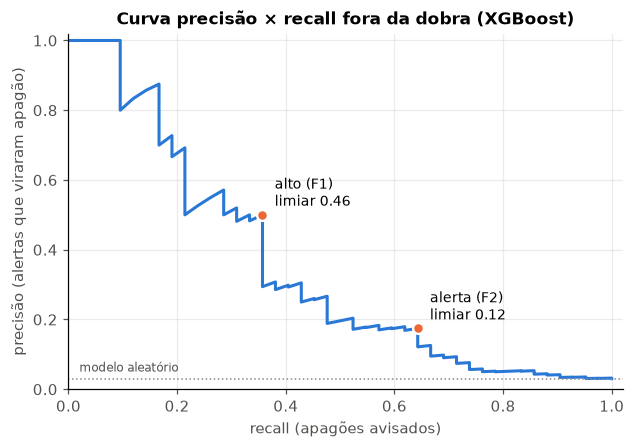

In [17]:
prec, rec, lim = precision_recall_curve(y_oof, p_oof)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(rec, prec, color=AZUL, lw=2)
for t, nome in [(LIMIAR, "alerta (F2)"), (LIMIAR_ALTO, "alto (F1)")]:
    prev = p_oof >= t
    r, p = recall_score(y_oof, prev), precision_score(y_oof, prev)
    ax.scatter([r], [p], color=LARANJA, s=50, zorder=3, edgecolor="white", lw=1.5)
    ax.annotate(f"{nome}\nlimiar {t:.2f}", (r, p), xytext=(8, 6), textcoords="offset points", fontsize=9)
ax.axhline(y_oof.mean(), color=CINZA, ls=":", lw=1)
ax.text(0.02, y_oof.mean() + 0.02, "modelo aleatório", fontsize=8, color="#52514e")
ax.set_xlabel("recall (apagões avisados)"); ax.set_ylabel("precisão (alertas que viraram apagão)")
ax.set_title(f"Curva precisão × recall fora da dobra ({ESCOLHIDO})")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
plt.show()

**Como isso se encaixa nas faixas da API.** A API (`POST /api/previsoes`) abre alerta a partir de
probabilidade 0,4 (Atenção) e marca Alto a partir de 0,7. Os limiares escolhidos acima não são 0,4 e
0,7, e as probabilidades de um modelo treinado com peso de classe ficam infladas. Em vez de mexer na API,
o `enviar_previsao.py` envia um **score de risco (0 a 1)**, obtido da probabilidade do modelo por uma
função **monótona e linear por partes** (`para_probabilidade_api` em `luzvital.py`):

| Probabilidade do modelo | Score de risco enviado à API | Nível na API |
| --- | --- | --- |
| 0 até o limiar de alerta | 0 a 0,4 | Baixo, sem alerta |
| limiar de alerta até o limiar alto | 0,4 a 0,7 | Atenção, abre alerta |
| limiar alto até 1 | 0,7 a 1 | Alto, abre alerta |

Assim a regra de 0,4 da API passa a significar exatamente "o modelo passou do limiar F2", e a ordem
entre os dias não muda. **O score não é uma probabilidade:** um score de 0,82 diz que o dia está na faixa
Alto, não que há 82% de chance de apagão. O campo do JSON se chama `probabilidade` só porque é o contrato
da API.

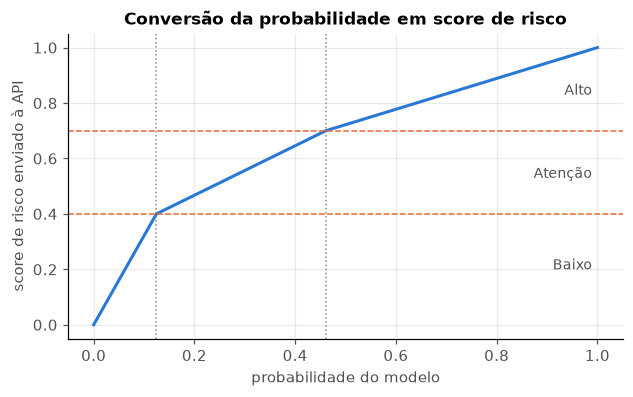

In [18]:
xs = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(xs, [para_probabilidade_api(v, LIMIAR, LIMIAR_ALTO) for v in xs], color=AZUL, lw=2)
for v, cor in [(0.4, LARANJA), (0.7, LARANJA)]:
    ax.axhline(v, color=cor, ls="--", lw=1)
ax.axvline(LIMIAR, color=CINZA, ls=":", lw=1); ax.axvline(LIMIAR_ALTO, color=CINZA, ls=":", lw=1)
ax.text(0.99, 0.2, "Baixo", ha="right", fontsize=9, color="#52514e")
ax.text(0.99, 0.53, "Atenção", ha="right", fontsize=9, color="#52514e")
ax.text(0.99, 0.83, "Alto", ha="right", fontsize=9, color="#52514e")
ax.set_xlabel("probabilidade do modelo"); ax.set_ylabel("score de risco enviado à API")
ax.set_title("Conversão da probabilidade em score de risco")
plt.show()

## 8. Resultados em treino e teste

### 8.1 Os três modelos lado a lado

Cada modelo com a sua melhor combinação e o **seu** limiar F2 (escolhido do mesmo jeito, fora da dobra
no treino). Três colunas por métrica:
- **treino (ajuste)**: o modelo prevendo os dias em que foi treinado. Mede o quanto ele decorou.
- **validação (CV)**: probabilidades fora da dobra no treino. É o que se esperava antes de olhar o teste.
- **teste**: 2024 e 2025, nunca vistos.

In [19]:
def metricas(y, p, limiar):
    prev = (p >= limiar).astype(int)
    return {"PR-AUC": average_precision_score(y, p), "recall": recall_score(y, prev),
            "precisão": precision_score(y, prev, zero_division=0), "F1": f1_score(y, prev)}

linhas, limiares = [], {}
for nome, b in buscas.items():
    m = b.best_estimator_
    p_cv = prob_fora_da_dobra(m, X_tr, y_tr, cv)
    t = limiar_fbeta(y_tr.loc[p_cv.index], p_cv, 2)
    limiares[nome] = t
    for conjunto, yy, pp in [("treino (ajuste)", y_tr, m.predict_proba(X_tr)[:, 1]),
                             ("validação (CV)", y_tr.loc[p_cv.index], p_cv),
                             ("teste", y_te, m.predict_proba(X_te)[:, 1])]:
        linhas.append({"modelo": nome, "conjunto": conjunto, "limiar": round(t, 3), **metricas(yy, pp, t)})

lado_a_lado = pd.DataFrame(linhas).pivot(index="modelo", columns="conjunto", values=["PR-AUC", "recall", "precisão", "F1"])
lado_a_lado = lado_a_lado.reindex(columns=["treino (ajuste)", "validação (CV)", "teste"], level=1).round(3)
lado_a_lado

PR-AUC                                recall                              precisão                                    F1  \
conjunto            treino (ajuste) validação (CV)  teste treino (ajuste) validação (CV)  teste treino (ajuste) validação (CV)  teste treino (ajuste)   
modelo                                                                                                                                                  
Random Forest                 0.673          0.325  0.314           0.925          0.548  0.422           0.340          0.215  0.345           0.497   
Regressão logística           0.401          0.326  0.404           0.623          0.524  0.467           0.260          0.262  0.356           0.367   
XGBoost                       0.616          0.351  0.314           0.906          0.643  0.622           0.183          0.174  0.272           0.304   

                                           
conjunto            validação (CV)  teste  
modelo                                     
Random Forest                0.309  0.380  
Regressão logística          0.349  0.404  
XGBoost                      0.274  0.378

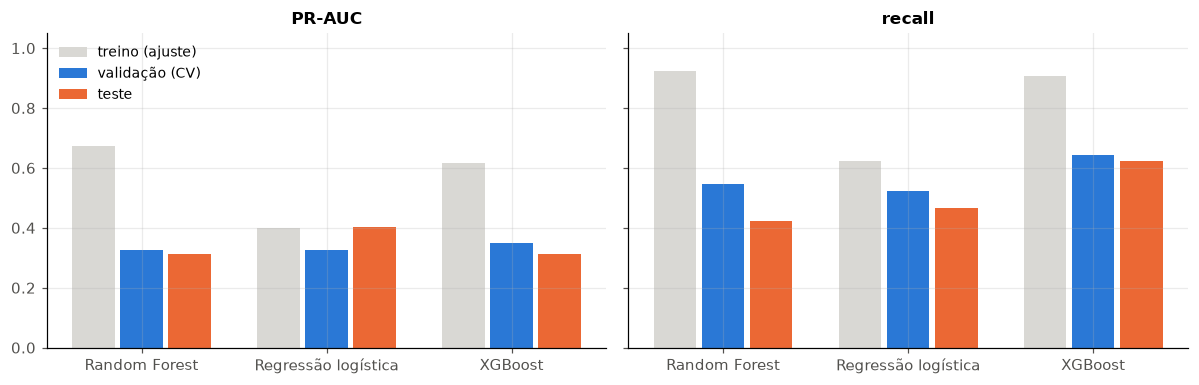

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
conjuntos = ["treino (ajuste)", "validação (CV)", "teste"]
cores = [CINZA_CLARO, AZUL, LARANJA]
for ax, met in zip(axs, ["PR-AUC", "recall"]):
    largura = 0.26
    for i, (c, cor) in enumerate(zip(conjuntos, cores)):
        vals = lado_a_lado[(met, c)]
        ax.bar(np.arange(len(vals)) + (i - 1) * largura, vals.values, width=largura - 0.03, color=cor, label=c)
    ax.set_xticks(range(len(vals)), vals.index)
    ax.set_title(met); ax.set_ylim(0, 1.05)
axs[0].legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

**Overfitting.**
- Random Forest e XGBoost decoram o treino: PR-AUC de 0,67 e 0,62 no ajuste contra 0,31 no teste, e
  recall acima de 0,9 no ajuste contra 0,42 e 0,62 no teste. A validação cruzada (0,33 e 0,35) previu bem
  o resultado do teste. A queda do ajuste para o teste é overfitting, não azar na divisão.
- A regressão logística quase não tem diferença entre ajuste e teste (0,40 e 0,40) e teve a melhor PR-AUC
  no teste. Ela ordena um pouco melhor os dias de 2024 e 2025, mas no seu limiar F2 avisa menos apagões
  (recall 0,47, 21 de 45) que o XGBoost (0,62, 28 de 45).
- O modelo foi escolhido pela validação, antes de olhar o teste, e a escolha foi mantida. Trocar pela
  logística depois de ver o teste seria usar o teste para escolher o modelo.

### 8.2 O modelo escolhido no teste (2024 e 2025)

Modelo: XGBoost (xgb-v1), limiar 0.125
Recall 0.622, Precisão 0.272, F1 0.378, PR-AUC 0.314 (PR-AUC de um modelo aleatório = 0.062)
Dias de apagão avisados: 28 de 45
Alarmes falsos: 75 em 731 dias (38 por ano), alertas no total: 103 (52 por ano)


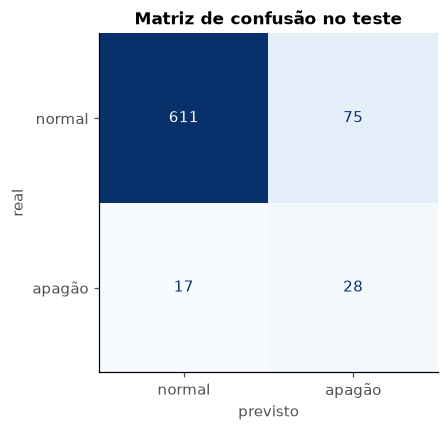

In [21]:
p_te = pd.Series(modelo_final.predict_proba(X_te)[:, 1], index=X_te.index)
prev_te = (p_te >= LIMIAR).astype(int)
m_te = metricas(y_te, p_te, LIMIAR)
cm = confusion_matrix(y_te, prev_te)
tn, fp, fn, tp = cm.ravel()

print(f"Modelo: {ESCOLHIDO} ({VERSAO}), limiar {LIMIAR:.3f}")
print(f"Recall {m_te['recall']:.3f}, Precisão {m_te['precisão']:.3f}, F1 {m_te['F1']:.3f}, PR-AUC {m_te['PR-AUC']:.3f} "
      f"(PR-AUC de um modelo aleatório = {y_te.mean():.3f})")
print(f"Dias de apagão avisados: {tp} de {tp + fn}")
print(f"Alarmes falsos: {fp} em {len(y_te)} dias ({fp / 2:.0f} por ano), alertas no total: {tp + fp} ({(tp + fp) / 2:.0f} por ano)")

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(cm, display_labels=["normal", "apagão"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.grid(False)
ax.set_title("Matriz de confusão no teste")
plt.show()

In [22]:
tab = pd.DataFrame({
    "UCs atingidas": diario.loc[y_te.index[y_te == 1], "ucs_atingidas"],
    "rajada (m/s)": X_te.loc[y_te == 1, "rajada_max_ms"],
    "chuva (mm)": X_te.loc[y_te == 1, "chuva_mm"],
    "prob. modelo": p_te[y_te == 1].round(3),
    "score de risco": p_te[y_te == 1].map(lambda v: round(para_probabilidade_api(v, LIMIAR, LIMIAR_ALTO), 2)),
})
tab["avisado?"] = np.where(tab["prob. modelo"] >= LIMIAR, "sim", "NÃO")
print(f"Os {len(tab)} dias de apagão do teste, do maior para o menor:")
tab.sort_values("UCs atingidas", ascending=False)

Os 45 dias de apagão do teste, do maior para o menor:


,UCs atingidas,rajada (m/s),chuva (mm),prob. modelo,score de risco,avisado?
data,,,,,,
2025-12-10,4204739,23.0,16.6,0.660,0.81,sim
2024-10-11,3063592,20.7,21.2,0.747,0.86,sim
2025-09-22,2088091,19.2,32.4,0.560,0.76,sim
2025-01-07,1171326,8.9,9.4,0.132,0.41,sim
2024-12-20,1168986,20.5,30.4,0.766,0.87,sim
2024-08-31,964965,6.5,0.0,0.054,0.17,NÃO
2025-10-14,950541,8.4,0.0,0.027,0.09,NÃO
2025-12-09,900321,16.1,59.4,0.483,0.71,sim
2025-12-13,782337,9.9,40.2,0.202,0.47,sim


In [23]:
print("Eventos conhecidos que caem no teste:")
for data, nome in EVENTOS.items():
    if pd.Timestamp(data) in p_te.index:
        v = p_te[data]
        print(f"  {nome}: prob. {v:.3f}, score de risco {para_probabilidade_api(v, LIMIAR, LIMIAR_ALTO):.2f}")
p_tr_evento = modelo_final.predict_proba(X.loc[["2023-11-03"]])[:, 1][0]
print(f"  (03/11/2023 está no treino: prob. no ajuste {p_tr_evento:.3f})")

faixas = p_te.map(lambda v: para_probabilidade_api(v, LIMIAR, LIMIAR_ALTO)).pipe(
    pd.cut, bins=[-0.01, 0.4 - 1e-9, 0.7 - 1e-9, 1.01], labels=["Baixo", "Atenção", "Alto"])
pd.crosstab(faixas, y_te.map({0: "dia normal", 1: "dia de apagão"}), margins=True, margins_name="total").rename_axis("faixa na API", axis=0)

Eventos conhecidos que caem no teste:
  Temporal de 11/10/2024: prob. 0.747, score de risco 0.86
  Ventania de 10/12/2025: prob. 0.660, score de risco 0.81
  (03/11/2023 está no treino: prob. no ajuste 0.818)


apagao,dia de apagão,dia normal,total
faixa na API,,,
Baixo,17,611,628
Atenção,13,58,71
Alto,15,17,32
total,45,686,731


**Onde o modelo erra.** Os dias de apagão perdidos e os alarmes falsos, olhados de perto:

In [24]:
ucs_te = diario.loc[y_te.index, "ucs_atingidas"]
perdidos = y_te[(y_te == 1) & (p_te < LIMIAR)].index
pegos = y_te[(y_te == 1) & (p_te >= LIMIAR)].index
falsos = y_te[(y_te == 0) & (p_te >= LIMIAR)].index
vizinho = lambda d: any(y.get(d + pd.Timedelta(days=k), 0) == 1 for k in (-1, 1))

pd.DataFrame({
    "dias": [len(pegos), len(perdidos), len(falsos)],
    "rajada mediana (m/s)": [X_te.loc[i, "rajada_max_ms"].median() for i in (pegos, perdidos, falsos)],
    "chuva mediana (mm)": [X_te.loc[i, "chuva_mm"].median() for i in (pegos, perdidos, falsos)],
    "UCs atingidas (mediana)": [ucs_te[i].median() for i in (pegos, perdidos, falsos)],
}, index=["apagões avisados", "apagões perdidos", "alarmes falsos"]).round(1)

,dias,rajada mediana (m/s),chuva mediana (mm),UCs atingidas (mediana)
apagões avisados,28,14.0,12.3,484471.5
apagões perdidos,17,9.2,0.6,407100.0
alarmes falsos,75,12.3,5.4,161855.0


In [25]:
grandes = ucs_te[y_te == 1].sort_values(ascending=False)
print(f"Dia típico do teste: mediana de {ucs_te.median():,.0f} UCs atingidas".replace(",", "."))
print(f"Apagões com mais de 1 milhão de UCs avisados: {(p_te[grandes[grandes > 1e6].index] >= LIMIAR).sum()} de {(grandes > 1e6).sum()}")
print(f"Os 10 maiores apagões do teste avisados: {(p_te[grandes.index[:10]] >= LIMIAR).sum()} de 10")
print(f"Perdidos sem tempestade (rajada < 10 m/s e chuva < 1 mm): {((X_te.loc[perdidos, 'rajada_max_ms'] < 10) & (X_te.loc[perdidos, 'chuva_mm'] < 1)).sum()} de {len(perdidos)}")
print(f"Perdidos colados a outro dia de apagão (dia seguinte ou anterior): {sum(vizinho(d) for d in perdidos)}"
      f": {[d.strftime('%d/%m/%Y') for d in perdidos if vizinho(d)]}")
print(f"Alarmes falsos em dias com mais que o dobro das UCs de um dia típico: {(ucs_te[falsos] > 2 * ucs_te.median()).sum()} de {len(falsos)}")

Dia típico do teste: mediana de 72.863 UCs atingidas


Apagões com mais de 1 milhão de UCs avisados: 5 de 5
Os 10 maiores apagões do teste avisados: 8 de 10
Perdidos sem tempestade (rajada < 10 m/s e chuva < 1 mm): 8 de 17
Perdidos colados a outro dia de apagão (dia seguinte ou anterior): 3: ['12/10/2024', '13/10/2024', '08/12/2025']
Alarmes falsos em dias com mais que o dobro das UCs de um dia típico: 43 de 75


**Leitura do teste.**
- Com o limiar 0,125, o modelo avisou **28 dos 45 dias de apagão** de 2024 e 2025 (recall 0,62), com
  precisão 0,27: de cada 4 alertas, 1 virou apagão em massa. São cerca de 52 alertas por ano, 1 por
  semana em média, concentrados na época de chuva. A PR-AUC (0,31) é 5 vezes a de um modelo aleatório (0,06).
- Os maiores foram avisados: os 5 dias com mais de 1 milhão de UCs atingidas e 8 dos 10 maiores.
  11/10/2024 e 10/12/2025 caem na faixa Alto da API (score de risco 0,86 e 0,81).
- A faixa Alto acerta perto de metade das vezes (15 dos 32 dias Alto foram apagão). A faixa Atenção
  acerta 13 de 71.
- Os 17 perdidos são, na maior parte, dias sem temporal no Mirante de Santana: rajada mediana de 9,2 m/s
  e chuva de 0,6 mm, contra 14,1 m/s e 12,3 mm nos avisados. Em 8 deles a rajada ficou abaixo de 10 m/s e a
  chuva abaixo de 1 mm. Há três explicações prováveis: temporal localizado longe da estação (uma estação
  para os 24 municípios da área da Enel SP), falha de rede sem relação com o clima, e dias colados a um
  apagão (12 e 13/10/2024, logo depois de 11/10, e 08/12/2025).
- Os alarmes falsos não são dias calmos. A mediana deles é de 162 mil UCs atingidas, mais que o dobro de
  um dia típico (73 mil), e 43 dos 75 passaram desse dobro. São dias de rede sob estresse que não chegaram
  ao limite do rótulo.

### 8.3 Importância das variáveis

Duas medidas: a **importância por permutação no teste** (quanto a PR-AUC cai quando os valores de uma
variável são embaralhados, repetido 30 vezes) e a importância interna do modelo.

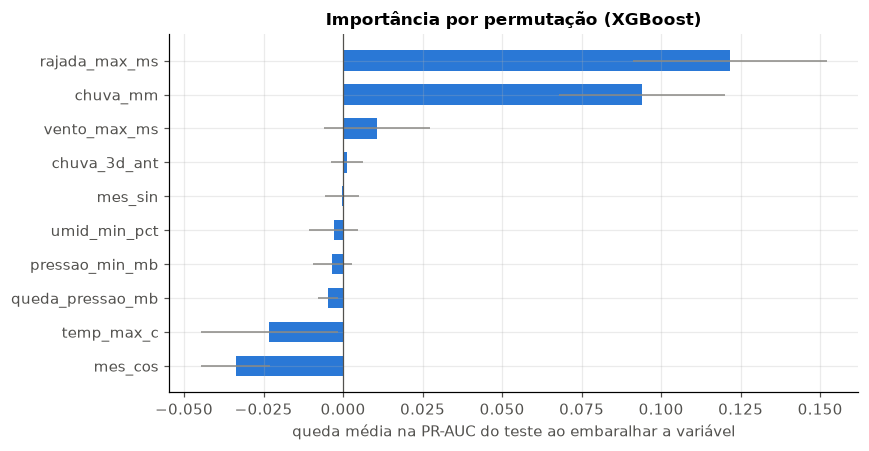

,"queda na PR-AUC (permutação, teste)",desvio,importância interna
rajada_max_ms,0.122,0.030,0.286
chuva_mm,0.094,0.026,0.119
vento_max_ms,0.011,0.017,0.119
chuva_3d_ant,0.001,0.005,0.066
mes_sin,-0.000,0.005,0.068
umid_min_pct,-0.003,0.008,0.071
pressao_min_mb,-0.003,0.006,0.073
queda_pressao_mb,-0.005,0.003,0.064
temp_max_c,-0.023,0.022,0.077
mes_cos,-0.034,0.011,0.056


In [26]:
perm = permutation_importance(modelo_final, X_te, y_te, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"queda na PR-AUC (permutação, teste)": perm.importances_mean, "desvio": perm.importances_std}, index=ATRIBUTOS)
interno = modelo_final.named_steps["modelo"]
if hasattr(interno, "feature_importances_"):
    imp["importância interna"] = interno.feature_importances_
else:
    imp["|coeficiente| (padronizado)"] = np.abs(interno.coef_[0])
imp = imp.sort_values("queda na PR-AUC (permutação, teste)", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.iloc[:, 0], xerr=imp["desvio"], color=AZUL, height=0.6, error_kw={"ecolor": CINZA, "lw": 1})
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("queda média na PR-AUC do teste ao embaralhar a variável")
ax.set_title(f"Importância por permutação ({ESCOLHIDO})")
plt.tight_layout(); plt.show()
imp.iloc[::-1].round(3)

**O que pesa no modelo.** Rajada e chuva do dia carregam quase todo o resultado: embaralhar a rajada
derruba a PR-AUC do teste em 0,12, e a chuva em 0,09. O vento médio contribui pouco (0,01) e a chuva dos 3
dias anteriores quase nada.

Pressão mínima, queda de pressão, umidade e o seno do mês ficam perto de zero. Temperatura máxima e o
cosseno do mês ficam negativos: embaralhá-los *melhora* o teste. O modelo aprendeu com eles alguma relação
de 2019 a 2023 que não se repetiu em 2024 e 2025 (2025 teve apagões em julho, agosto e setembro, fora da
época de chuva). São candidatos a sair numa próxima versão, decidido com validação no treino e não por este
gráfico, que usa o teste.

**Por que a queda de pressão não separa os grupos.** Na faixa tropical, a pressão sobe e desce duas vezes
por dia por causa da maré atmosférica (a maré barométrica semidiurna, provocada pelo aquecimento solar). Em
São Paulo essa oscilação é de 2 a 3 mB, com máxima por volta das 10h e mínima no fim da tarde. A "maior
queda em 3 h" quase sempre é essa descida da tarde, que acontece todo dia, com ou sem temporal; por isso a
mediana é 2,2 mB nos dois grupos. A queda causada por uma frente fria acontece ao longo de 12 a 24 h e se
perde dentro do ciclo diário. A pressão mínima do dia, que capta o nível e não a oscilação, separa um pouco
melhor (922 contra 925 mB), mas também não pesa no modelo.

## 9. Comparação: só com o que se sabe na véspera

O modelo principal supõe que a previsão do tempo para amanhã é tão boa quanto o clima observado. Para
medir o peso dessa premissa, treinamos o mesmo tipo de modelo, com a mesma grade, usando só dados
**já observados na véspera**: o clima de D-1 (as 7 variáveis), a rajada de D-2, a chuva dos 3 dias
anteriores e o mês. Os dias cujo D-1 ou D-2 cai na falha do anemômetro saem do treino.

In [27]:
Xv = montar_atributos_vespera(diario)
falha_v = (diario["falha_anemometro"].shift(1, fill_value=0) == 1) | (diario["falha_anemometro"].shift(2, fill_value=0) == 1)
no_treino_v = eh_treino & ~falha_v & (diario.index > diario.index[1])
Xv_tr, yv_tr, Xv_te = Xv[no_treino_v], y[no_treino_v], Xv[no_teste]

modelo_v, grade_v = CANDIDATOS[ESCOLHIDO]
busca_v = GridSearchCV(modelo_v, grade_v, cv=cv, scoring=METRICAS, refit="pr_auc", n_jobs=-1).fit(Xv_tr, yv_tr)
p_oof_v = prob_fora_da_dobra(busca_v.best_estimator_, Xv_tr, yv_tr, cv)
limiar_v = limiar_fbeta(yv_tr.loc[p_oof_v.index], p_oof_v, 2)
p_te_v = busca_v.best_estimator_.predict_proba(Xv_te)[:, 1]

compara_v = pd.DataFrame({
    "clima do dia (principal)": {"PR-AUC validação (CV)": buscas[ESCOLHIDO].best_score_, "limiar F2": LIMIAR, **metricas(y_te, p_te, LIMIAR)},
    "só a véspera": {"PR-AUC validação (CV)": busca_v.best_score_, "limiar F2": limiar_v, **metricas(y_te, p_te_v, limiar_v)},
}).T.rename(columns={"PR-AUC": "PR-AUC teste", "recall": "recall teste", "precisão": "precisão teste", "F1": "F1 teste"})
compara_v["apagões avisados (de 45)"] = [int(((p_te >= LIMIAR) & (y_te == 1)).sum()), int(((p_te_v >= limiar_v) & (y_te == 1)).sum())]
compara_v["alertas por ano"] = [(p_te >= LIMIAR).sum() / 2, (p_te_v >= limiar_v).sum() / 2]
compara_v.round(3)

,PR-AUC validação (CV),limiar F2,PR-AUC teste,recall teste,precisão teste,F1 teste,apagões avisados (de 45),alertas por ano
clima do dia (principal),0.355,0.125,0.314,0.622,0.272,0.378,28,51.5
só a véspera,0.091,0.126,0.160,0.622,0.111,0.189,28,126.0


**O peso da premissa.** Só com o que se sabe na véspera, a PR-AUC na validação cai de 0,355 para 0,091 e
no teste de 0,31 para 0,16. Para avisar os mesmos 28 apagões, o modelo da véspera precisa de 126 alertas por
ano em vez de 52 (precisão 0,11). O clima de ontem diz pouco sobre o temporal de amanhã, porque o temporal de
verão em São Paulo se forma em poucas horas.

Quase todo o valor do modelo vem, portanto, de saber como vai estar o tempo no próprio dia. Em produção ele
recebe a previsão meteorológica da véspera, e o desempenho real deve ficar entre as duas linhas da tabela,
mais perto da primeira quanto melhor for a previsão de rajada e chuva. Essa é a principal limitação do
trabalho.

## 10. Análise de sensibilidade: rótulo relativo

O número de interrupções cresce ao longo da série (a mediana diária subiu cerca de 70% entre 2019 e
2025). Com um limite fixo, 2024 e 2025 têm o dobro da proporção de dias de apagão do treino. Para ver se
as conclusões dependem disso, testamos um **rótulo relativo**: dia de apagão é o dia com **mais de 4 vezes
a mediana móvel das UCs atingidas nos 90 dias anteriores** (o próprio dia não entra na mediana). Esse
rótulo acompanha o nível de cada época.

Mesmo tipo de modelo, mesmos hiperparâmetros do principal; o limiar é escolhido do mesmo jeito (F2 fora
da dobra). **O modelo principal não muda.**

In [28]:
mediana_90 = diario["ucs_atingidas"].rolling(90, min_periods=60).median().shift(1)
y_rel = (diario["ucs_atingidas"] > 4 * mediana_90).astype(int)
tem_base = mediana_90.notna()

contagem = pd.DataFrame({"rótulo principal (p97 fixo)": diario.groupby(diario.index.year)["apagao"].sum(),
                         "rótulo relativo (4× mediana 90d)": y_rel[tem_base].groupby(diario.index[tem_base].year).sum()})
print("Dias de apagão por ano em cada rótulo:")
display(contagem.T)
print("Eventos conhecidos no rótulo relativo:", {d: int(y_rel[d]) for d in EVENTOS})
print(f"Concordância entre os rótulos (dias com base de 90 dias): {(y_rel[tem_base] == y[tem_base]).mean():.1%}; "
      f"positivos em comum: {int(((y_rel == 1) & (y == 1)).sum())}")

Dias de apagão por ano em cada rótulo:


data,2019,2020,2021,2022,2023,2024,2025
rótulo principal (p97 fixo),12,5,5,12,21,18,27
rótulo relativo (4× mediana 90d),12,19,11,25,27,24,23


Eventos conhecidos no rótulo relativo: {'2023-11-03': 1, '2024-10-11': 1, '2025-12-10': 1}
Concordância entre os rótulos (dias com base de 90 dias): 97.3%; positivos em comum: 83


In [29]:
no_treino_r = no_treino & tem_base
Xr_tr, yr_tr, yr_te = X[no_treino_r], y_rel[no_treino_r], y_rel[no_teste]
modelo_r = clone(modelo_final)
p_oof_r = prob_fora_da_dobra(modelo_r, Xr_tr, yr_tr, cv)
limiar_r = limiar_fbeta(yr_tr.loc[p_oof_r.index], p_oof_r, 2)
modelo_r.fit(Xr_tr, yr_tr)
p_te_r = modelo_r.predict_proba(X_te)[:, 1]

sens = pd.DataFrame({
    "principal (p97 fixo)": {"dias de apagão no teste": int(y_te.sum()), "% apagão treino": y_tr.mean(), "% apagão teste": y_te.mean(),
                             "PR-AUC fora da dobra (treino)": average_precision_score(y_oof, p_oof), "limiar F2": LIMIAR, **metricas(y_te, p_te, LIMIAR)},
    "relativo (4× mediana 90d)": {"dias de apagão no teste": int(yr_te.sum()), "% apagão treino": yr_tr.mean(), "% apagão teste": yr_te.mean(),
                                  "PR-AUC fora da dobra (treino)": average_precision_score(yr_tr.loc[p_oof_r.index], p_oof_r), "limiar F2": limiar_r, **metricas(yr_te, p_te_r, limiar_r)},
}).T
display(sens.round(3))

perm_r = permutation_importance(modelo_r, X_te, yr_te, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=-1)
ordem = pd.DataFrame({"principal": pd.Series(perm.importances_mean, index=ATRIBUTOS).rank(ascending=False).astype(int),
                      "relativo": pd.Series(perm_r.importances_mean, index=ATRIBUTOS).rank(ascending=False).astype(int)}).sort_values("principal")
print("Posição de cada variável na importância por permutação (1 = mais importante):")
ordem.T

,dias de apagão no teste,% apagão treino,% apagão teste,PR-AUC fora da dobra (treino),limiar F2,PR-AUC,recall,precisão,F1
principal (p97 fixo),45.0,0.031,0.062,0.351,0.125,0.314,0.622,0.272,0.378
relativo (4× mediana 90d),47.0,0.055,0.064,0.280,0.196,0.383,0.766,0.267,0.396


Posição de cada variável na importância por permutação (1 = mais importante):


,rajada_max_ms,chuva_mm,vento_max_ms,chuva_3d_ant,mes_sin,umid_min_pct,pressao_min_mb,queda_pressao_mb,temp_max_c,mes_cos
principal,1,2,3,4,5,6,7,8,9,10
relativo,2,1,8,6,3,10,4,7,9,5


**As conclusões mudam com o rótulo relativo?** Não.
- Os dias de apagão ficam mais bem distribuídos entre os anos (11 a 27 por ano, contra 5 a 27 no rótulo
  fixo), e a proporção no treino (5,5%) fica perto da do teste (6,4%). Os dois rótulos concordam em 97% dos
  dias, e os três eventos conhecidos são positivos nos dois.
- O desempenho no teste é parecido, um pouco melhor: PR-AUC 0,38, recall 0,77 e F1 0,40, contra 0,31,
  0,62 e 0,38 no principal.
- Rajada e chuva continuam as duas variáveis mais importantes, só trocam de posição. A pressão mínima e o
  seno do mês sobem no ranking, porque o rótulo relativo também marca dias moderados em épocas de poucas
  interrupções.

O crescimento das interrupções ao longo dos anos não é o que explica o resultado do modelo principal.

## 11. Modelo salvo

In [30]:
Path("modelo").mkdir(exist_ok=True)
pacote = {
    "modelo": modelo_final, "versao": VERSAO, "tipo": ESCOLHIDO, "atributos": ATRIBUTOS,
    "limiar": LIMIAR, "limiar_alto": LIMIAR_ALTO, "limite_rotulo_ucs": float(LIMITE_UCS),
    "treino": "2019-01-01 a 2023-12-31 (sem os dias de falha do anemômetro)",
    "hiperparametros": comparacao.loc[ESCOLHIDO, "melhores hiperparâmetros"],
}
joblib.dump(pacote, "modelo/modelo_luzvital.joblib")

meta = {k: v for k, v in pacote.items() if k != "modelo"}
meta["metricas_teste"] = {k: round(float(v), 4) for k, v in m_te.items()}
meta["matriz_confusao_teste"] = {"vn": int(tn), "fp": int(fp), "fn": int(fn), "vp": int(tp)}
Path("modelo/metadados.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(json.dumps(meta, ensure_ascii=False, indent=2, default=str))

{
  "versao": "xgb-v1",
  "tipo": "XGBoost",
  "atributos": [
    "rajada_max_ms",
    "vento_max_ms",
    "chuva_mm",
    "pressao_min_mb",
    "queda_pressao_mb",
    "temp_max_c",
    "umid_min_pct",
    "chuva_3d_ant",
    "mes_sin",
    "mes_cos"
  ],
  "limiar": 0.12454994022846222,
  "limiar_alto": 0.4607660472393036,
  "limite_rotulo_ucs": 316590.75,
  "treino": "2019-01-01 a 2023-12-31 (sem os dias de falha do anemômetro)",
  "hiperparametros": {
    "learning_rate": 0.03,
    "max_depth": 2,
    "n_estimators": 150,
    "scale_pos_weight": 5.6
  },
  "metricas_teste": {
    "PR-AUC": 0.3139,
    "recall": 0.6222,
    "precisão": 0.2718,
    "F1": 0.3784
  },
  "matriz_confusao_teste": {
    "vn": 611,
    "fp": 75,
    "fn": 17,
    "vp": 28
  }
}


Exemplo de uso, igual ao que `enviar_previsao.py` faz: a previsão do tempo de um dia de temporal entra,
sai o JSON do contrato da API.

In [31]:
exemplo = pd.DataFrame({"rajada_max_ms": [19.0], "vento_max_ms": [6.0], "chuva_mm": [25.0], "pressao_min_mb": [917.0],
                        "queda_pressao_mb": [2.5], "temp_max_c": [31.0], "umid_min_pct": [45.0], "chuva_3d_ant": [10.0]},
                       index=pd.DatetimeIndex(["2026-11-20"]))
ang = 2 * np.pi * exemplo.index.month / 12
exemplo["mes_sin"], exemplo["mes_cos"] = np.sin(ang), np.cos(ang)
p = modelo_final.predict_proba(exemplo[ATRIBUTOS])[:, 1][0]
print(f"probabilidade do modelo {p:.3f}, score de risco enviado no campo \"probabilidade\":")
print(json.dumps({"data": "2026-11-20", "probabilidade": round(para_probabilidade_api(p, LIMIAR, LIMIAR_ALTO), 3), "versaoModelo": VERSAO}))

probabilidade do modelo 0.801, score de risco enviado no campo "probabilidade":
{"data": "2026-11-20", "probabilidade": 0.889, "versaoModelo": "xgb-v1"}


## 12. O que isso significa para o cidadão

- Em 2024 e 2025, o modelo teria avisado com antecedência **28 dos 45 dias de apagão em massa** na área
  da Enel SP, incluindo os 5 maiores, com mais de 1 milhão de UCs sem luz cada. Os temporais de 11/10/2024 e
  10/12/2025 já estariam na faixa Alto. Para quem tem concentrador de oxigênio ou insulina na geladeira,
  isso é tempo para carregar a bateria, combinar com um vizinho e saber onde fica o ponto com energia mais
  próximo.
- O custo é cerca de **um alerta por semana**, e a maioria não vira apagão em massa. Nos alertas da faixa
  Alto, metade se confirmou. O app pode usar a faixa Atenção para preparar (avisar, conferir a bateria) e a
  faixa Alto para acionar os voluntários.
- **17 apagões passaram sem aviso**, a maior parte em dias sem temporal na estação do Mirante de Santana. O
  alerta não substitui o plano de cada família: quem depende de energia precisa ter bateria e o contato de
  um vizinho mesmo sem alerta, e o check-in dos voluntários depois que a luz cai continua necessário.
- O modelo depende da previsão do tempo. Com só o clima da véspera, para pegar os mesmos apagões seriam 126
  alertas por ano em vez de 52.